# 01. 준비

## 01-0. 환경 세팅

In [1]:
import sys
assert sys.version_info >= (3, 10)

from packaging.version import Version
import sklearn
assert Version(sklearn.__version__) >= Version("1.6.1")

IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

if IS_COLAB:
    %pip install -q optuna torchmetrics

import torch
assert Version(torch.__version__) >= Version("2.6.0")

import matplotlib.pyplot as plt
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

## 01-1. 라이브러리 호출

In [2]:
import torch
import numpy as np

## 01-2. 장치 지정

In [3]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

## 01-3. 데이터 준비

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [5]:
X_train = torch.FloatTensor(X_train)
X_valid = torch.FloatTensor(X_valid)
X_test = torch.FloatTensor(X_test)
means = X_train.mean(dim=0, keepdims=True)
stds = X_train.std(dim=0, keepdims=True)
X_train = (X_train - means) / stds
X_valid = (X_valid - means) / stds
X_test = (X_test - means) / stds

y_train = torch.FloatTensor(y_train).view(-1, 1)
y_valid = torch.FloatTensor(y_valid).view(-1, 1)
y_test = torch.FloatTensor(y_test).view(-1, 1)

# 02. 모델 구현

## 02-1. 입력 특성

In [6]:
n_features = X_train.shape[1]
print(f"입력 변수: {n_features}")
# 매우 중요한 변수

입력 변수: 8


## 02-2. 선형 회귀 모델 만들기

In [7]:
# 선형 회귀: 배치 경사 하강법
torch.manual_seed(42)

w = torch.randn((n_features, 1), requires_grad=True)
b = torch.tensor(0., requires_grad=True)

lr = 0.4        # 학습률
n_epochs = 20   # 전체 훈련 세트를 20번 학습

for epoch in range(n_epochs):
    # ① 정방향 계산: 예측
    y_pred = X_train @ w + b

    # ② 손실 계산: 평균 제곱 오차(MSE)
    loss = ((y_pred - y_train) ** 2).mean()

    # ③ 역전파: 가중치와 편향의 그레이디언트 계산
    loss.backward()

    with torch.no_grad():
        # ④ 경사 하강법: 가중치와 편향 수정
        b -= lr * b.grad
        w -= lr * w.grad

        # ⑤ 다음 학습을 위해 그레이디언트 초기화
        b.grad.zero_()
        w.grad.zero_()

    print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}")

# 예측
X_new = X_test[:3]
with torch.no_grad():
  y_pred = X_new @ w + b

print(y_pred)

Epoch 1/20, Loss: 16.158456802368164
Epoch 2/20, Loss: 4.8793745040893555
Epoch 3/20, Loss: 2.255225419998169
Epoch 4/20, Loss: 1.3307636976242065
Epoch 5/20, Loss: 0.9680693745613098
Epoch 6/20, Loss: 0.8142675757408142
Epoch 7/20, Loss: 0.7417045831680298
Epoch 8/20, Loss: 0.7020700573921204
Epoch 9/20, Loss: 0.6765917539596558
Epoch 10/20, Loss: 0.6577963829040527
Epoch 11/20, Loss: 0.6426151394844055
Epoch 12/20, Loss: 0.6297222971916199
Epoch 13/20, Loss: 0.6184941530227661
Epoch 14/20, Loss: 0.6085968017578125
Epoch 15/20, Loss: 0.5998216271400452
Epoch 16/20, Loss: 0.592018723487854
Epoch 17/20, Loss: 0.5850691795349121
Epoch 18/20, Loss: 0.578873336315155
Epoch 19/20, Loss: 0.573345422744751
Epoch 20/20, Loss: 0.5684100389480591
tensor([[0.8916],
        [1.6480],
        [2.6577]])


## 02-3. API를 활용하여 선형 회귀

In [8]:
import torch.nn as nn

# 선형 회귀: 고수준 API를 이용한 배치 경사 하강법
torch.manual_seed(42)

# 모델 생성: 입력 특성 8개 → 출력 1개 (가중치와 편향 자동 생성)
model = nn.Linear(in_features=n_features, out_features=1)

# 경사 하강법 옵티마이저 및 손실 함수 설정
optimizer = torch.optim.SGD(model.parameters(), lr=lr)
mse = nn.MSELoss()  # 평균 제곱 오차(MSE)

# 훈련 함수 정의
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):
        # ① 정방향 계산: 현재 가중치와 편향으로 예측
        y_pred = model(X_train)

        # ② 손실 계산: 예측값과 정답의 평균 제곱 오차(MSE)
        loss = criterion(y_pred, y_train)

        # ③ 역전파: 가중치와 편향의 그레이디언트 계산
        loss.backward()

        # ④ 경사 하강법: 그레이디언트를 이용해 가중치와 편향 수정
        optimizer.step()

        # ⑤ 다음 학습을 위해 그레이디언트 초기화
        optimizer.zero_grad()

        # 에포크별 손실 출력
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}")

# 전체 훈련 데이터로 n_epochs번 학습
# 1에포크 = 전체 데이터 사용 + 가중치 1번 수정
train_bgd(model, optimizer, mse, X_train, y_train, n_epochs)

# ⑥ 학습 완료 후 새로운 데이터 예측
X_new = X_test[:3]  # 테스트 데이터 중 3개 선택

with torch.no_grad():  # 예측 시 그레이디언트 계산 및 추적 비활성화
    y_pred = model(X_new)  # 학습된 가중치와 편향으로 예측

y_pred

Epoch 1/20, Loss: 4.3378496170043945
Epoch 2/20, Loss: 0.7802939414978027
Epoch 3/20, Loss: 0.6253842115402222
Epoch 4/20, Loss: 0.6060433983802795
Epoch 5/20, Loss: 0.5956299304962158
Epoch 6/20, Loss: 0.587356686592102
Epoch 7/20, Loss: 0.5802990794181824
Epoch 8/20, Loss: 0.5741382241249084
Epoch 9/20, Loss: 0.5687101483345032
Epoch 10/20, Loss: 0.5639079809188843
Epoch 11/20, Loss: 0.5596511363983154
Epoch 12/20, Loss: 0.5558737516403198
Epoch 13/20, Loss: 0.5525194406509399
Epoch 14/20, Loss: 0.5495392084121704
Epoch 15/20, Loss: 0.5468900203704834
Epoch 16/20, Loss: 0.5445339679718018
Epoch 17/20, Loss: 0.5424376726150513
Epoch 18/20, Loss: 0.5405716300010681
Epoch 19/20, Loss: 0.5389097332954407
Epoch 20/20, Loss: 0.5374288558959961


tensor([[0.8061],
        [1.7116],
        [2.6973]])

# 03. MLP 모델 구현

## 03-1. MLP 구현

In [9]:
import torch.nn as nn

torch.manual_seed(42)

# MLP 회귀 모델 생성: 입력층 → 은닉층 2개 → 출력층
model = nn.Sequential(
    # ① 첫 번째 은닉층: 입력 특성 8개 → 뉴런 50개
    nn.Linear(n_features, 50),
    nn.ReLU(),  # 비선형 활성화 함수 적용

    # ② 두 번째 은닉층: 뉴런 50개 → 뉴런 40개
    nn.Linear(50, 40),
    nn.ReLU(),  # 비선형 활성화 함수 적용

    # ③ 출력층: 뉴런 40개 → 예측값 1개
    nn.Linear(40, 1)  # 회귀이므로 출력 활성화 함수 없음
)

# 경사 하강법 옵티마이저 및 손실 함수 설정
lr = 0.1  # 학습률
optimizer = torch.optim.SGD(model.parameters(), lr=lr)
mse = nn.MSELoss()  # 평균 제곱 오차(MSE)

# 훈련 함수 정의: 배치 경사 하강법
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):

        # ① 정방향 계산: 은닉층을 거쳐 예측값 계산
        y_pred = model(X_train)

        # ② 손실 계산: 예측값과 정답의 평균 제곱 오차
        loss = criterion(y_pred, y_train)

        # ③ 역전파: 모든 층의 가중치와 편향에 대한 그레이디언트 계산
        loss.backward()

        # ④ 경사 하강법: 모든 층의 가중치와 편향 수정
        optimizer.step()

        # ⑤ 다음 학습을 위해 그레이디언트 초기화
        optimizer.zero_grad()

        # 에포크별 손실 출력
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}")

# 전체 훈련 데이터를 n_epochs번 학습
# 1에포크 = 전체 데이터 사용 + 모든 가중치 1번 수정
train_bgd(model, optimizer, mse, X_train, y_train, n_epochs)

# ⑥ 학습 완료 후 새로운 데이터 예측
X_new = X_test[:3]  # 테스트 데이터 중 3개 선택

with torch.no_grad():  # 예측 시 그레이디언트 추적 비활성화
    y_pred = model(X_new)  # 학습된 MLP로 예측

y_pred

Epoch 1/20, Loss: 5.045480251312256
Epoch 2/20, Loss: 2.0523123741149902
Epoch 3/20, Loss: 1.0039883852005005
Epoch 4/20, Loss: 0.8570138216018677
Epoch 5/20, Loss: 0.7740675210952759
Epoch 6/20, Loss: 0.7225848436355591
Epoch 7/20, Loss: 0.6893726587295532
Epoch 8/20, Loss: 0.6669032573699951
Epoch 9/20, Loss: 0.650773823261261
Epoch 10/20, Loss: 0.6383934020996094
Epoch 11/20, Loss: 0.6281994581222534
Epoch 12/20, Loss: 0.6193399429321289
Epoch 13/20, Loss: 0.6113173365592957
Epoch 14/20, Loss: 0.6038705706596375
Epoch 15/20, Loss: 0.5968307852745056
Epoch 16/20, Loss: 0.5901118516921997
Epoch 17/20, Loss: 0.583646833896637
Epoch 18/20, Loss: 0.5774063467979431
Epoch 19/20, Loss: 0.5713554620742798
Epoch 20/20, Loss: 0.5654447674751282


tensor([[0.8370],
        [1.2752],
        [2.7642]])

## 03-2. DataLoader 이용

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 01-2에서 지정한 device를 그대로 사용 (CUDA / MPS / CPU)

# ① 데이터 준비: 입력(X)과 정답(y)을 하나의 데이터셋으로 묶음
train_dataset = TensorDataset(X_train, y_train)

# 미니배치 설정: 데이터를 32개씩 나누고, 에포크마다 순서를 섞음
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

torch.manual_seed(42)

# ② MLP 회귀 모델 생성: 입력층 → 은닉층 2개 → 출력층
model = nn.Sequential(
    # 첫 번째 은닉층: 입력 특성 8개 → 뉴런 50개
    nn.Linear(n_features, 50),
    nn.ReLU(),  # 비선형 활성화 함수 적용

    # 두 번째 은닉층: 뉴런 50개 → 뉴런 40개
    nn.Linear(50, 40),
    nn.ReLU(),  # 비선형 활성화 함수 적용

    # 출력층: 뉴런 40개 → 예측값 1개
    nn.Linear(40, 1)  # 회귀이므로 출력 활성화 함수 없음
)

# 모델의 가중치와 편향을 GPU 또는 CPU로 이동
model = model.to(device)

# ③ 경사 하강법 옵티마이저 및 손실 함수 설정
lr = 0.02  # 학습률
n_epochs = 20  # 전체 훈련 데이터를 20번 학습

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=lr,
    momentum=0  # 모멘텀 미사용: 일반적인 SGD
)

mse = nn.MSELoss()  # 평균 제곱 오차(MSE)

# ④ 미니배치 경사 하강법 훈련 함수 정의
def train(model, optimizer, criterion, train_loader, n_epochs):

    model.train()  # 모델을 훈련 모드로 설정

    for epoch in range(n_epochs):
        total_loss = 0.  # 현재 에포크의 손실 합계 초기화

        # DataLoader에서 32개씩 데이터를 꺼내 학습
        for X_batch, y_batch in train_loader:

            # 데이터를 모델과 동일한 장치(GPU 또는 CPU)로 이동
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # ① 정방향 계산: 현재 가중치와 편향으로 예측
            y_pred = model(X_batch)

            # ② 손실 계산: 현재 미니배치의 평균 제곱 오차
            loss = criterion(y_pred, y_batch)

            # 현재 배치의 손실값을 누적 (모니터링용)
            total_loss += loss.item()

            # ③ 역전파: 모든 층의 가중치와 편향에 대한 그레이디언트 계산
            loss.backward()

            # ④ 경사 하강법: 그레이디언트로 가중치와 편향 수정
            optimizer.step()

            # ⑤ 다음 미니배치를 위해 그레이디언트 초기화
            optimizer.zero_grad()

        # 한 에포크의 배치별 손실 평균 계산
        mean_loss = total_loss / len(train_loader)

        # 에포크별 손실 출력
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}")

# ⑤ 모델 훈련 실행
# 1에포크 = 전체 훈련 데이터 사용 (미니배치마다 가중치 수정)
train(model, optimizer, mse, train_loader, n_epochs)

# ⑥ 학습 완료 후 새로운 데이터 예측
model.eval()  # 모델을 평가 모드로 전환

X_new = X_test[:3]  # 테스트 데이터 중 3개 선택
X_new = X_new.to(device)  # 모델과 동일한 장치로 이동

with torch.no_grad():  # 예측 시 그레이디언트 추적 비활성화
    y_pred = model(X_new)  # 학습된 MLP로 예측

y_pred

Epoch 1/20, Loss: 0.5900
Epoch 2/20, Loss: 0.4046
Epoch 3/20, Loss: 0.3801
Epoch 4/20, Loss: 0.3629
Epoch 5/20, Loss: 0.3529
Epoch 6/20, Loss: 0.3520
Epoch 7/20, Loss: 0.3408
Epoch 8/20, Loss: 0.3427
Epoch 9/20, Loss: 0.3406
Epoch 10/20, Loss: 0.3378
Epoch 11/20, Loss: 0.3304
Epoch 12/20, Loss: 0.3267
Epoch 13/20, Loss: 0.3244
Epoch 14/20, Loss: 0.3220
Epoch 15/20, Loss: 0.3188
Epoch 16/20, Loss: 0.3148
Epoch 17/20, Loss: 0.3120
Epoch 18/20, Loss: 0.3111
Epoch 19/20, Loss: 0.3088
Epoch 20/20, Loss: 0.3083


tensor([[0.6891],
        [1.4307],
        [4.8824]])

# 04. 모델 평가

## 04-1. 검증 함수 (배치별 지표 평균)

In [11]:
# 검증 함수 정의: 학습된 모델의 예측 성능 확인
def evaluate(model, data_loader, metric_fn, aggregate_fn=torch.mean):

    model.eval()  # ① 평가 모드로 전환 (가중치 수정 X)

    metrics = []  # 배치별 손실을 저장할 리스트

    with torch.no_grad():  # 역전파가 필요 없으므로 미분 추적 비활성화

        # ② 검증 데이터를 32개씩 꺼냄
        for X_batch, y_batch in data_loader:

            # 모델과 동일한 장치(GPU 또는 CPU)로 이동
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # ③ 정방향 계산: 학습된 모델로 예측
            y_pred = model(X_batch)

            # ④ 손실 계산: 예측값과 실제 정답 비교
            metric = metric_fn(y_pred, y_batch)

            # ⑤ 현재 배치의 손실 저장
            metrics.append(metric)

    # ⑥ 배치별 손실을 하나의 텐서로 묶고 평균 계산
    return aggregate_fn(torch.stack(metrics))


# 검증 데이터 준비
valid_dataset = TensorDataset(X_valid, y_valid)

# 검증 데이터를 32개씩 나눔 (순서를 섞을 필요 없음)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

# 학습된 모델의 검증 MSE 계산
valid_mse = evaluate(model, valid_loader, mse)

valid_mse

tensor(0.3934)

## 04-2. 배치 사용 시 주의점 (전체 RMSE)

In [12]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# ① 검증 데이터 준비: 입력(X)과 정답(y)을 묶음
valid_dataset = TensorDataset(X_valid, y_valid)

# 검증 데이터를 32개씩 나눔 (순서를 섞을 필요 없음)
valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False
)

# ② 전체 RMSE 평가 함수 정의
def evaluate_rmse(model, data_loader):
    model.eval()  # 평가 모드로 전환

    total_squared_error = 0.0  # 전체 오차 제곱의 합
    total_count = 0           # 전체 데이터 개수

    with torch.no_grad():  # 평가 시 그레이디언트 추적 비활성화

        # 검증 데이터를 32개씩 꺼내 평가
        for X_batch, y_batch in data_loader:

            # 데이터를 모델과 동일한 장치(GPU 또는 CPU)로 이동
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # ① 정방향 계산: 학습된 모델로 예측
            y_pred = model(X_batch)

            # ② 오차 계산: 예측값과 실제 정답의 차이
            error = y_pred - y_batch

            # ③ 오차 제곱을 모두 더함 (배치별 MSE 계산 전 단계)
            total_squared_error += (error ** 2).sum().item()

            # ④ 전체 데이터 개수 누적
            total_count += y_batch.numel()

    # ⑤ 전체 MSE 계산: 오차 제곱의 합 ÷ 전체 데이터 개수
    mean_mse = total_squared_error / total_count

    # ⑥ 전체 RMSE 계산: MSE에 마지막으로 제곱근 적용
    rmse = mean_mse ** 0.5

    return rmse


# ③ 학습된 모델의 검증 RMSE 계산
valid_rmse = evaluate_rmse(model, valid_loader)

# 검증 결과 출력 (소수점 4자리)
print(f"Validation RMSE: {valid_rmse:.4f}")

Validation RMSE: 0.6273


## 04-3. TorchMetrics를 이용한 평가

In [13]:
import torchmetrics

# ① TorchMetrics를 이용한 모델 평가 함수
def evaluate_tm(model, data_loader, metric):

    model.eval()  # 평가 모드로 전환 (가중치 학습 X)

    metric.reset()  # 이전 평가 결과 초기화

    with torch.no_grad():  # 평가 시 그레이디언트 추적 비활성화

        # ② 검증 데이터를 미니배치 단위로 꺼냄
        for X_batch, y_batch in data_loader:

            # 모델과 동일한 장치(GPU 또는 CPU)로 이동
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # ③ 정방향 계산: 학습된 모델로 예측
            y_pred = model(X_batch)

            # ④ 현재 배치의 예측 오차를 평가 지표에 누적
            metric.update(y_pred, y_batch)

    # ⑤ 전체 배치의 결과를 종합하여 최종 평가 지표 계산
    return metric.compute()


# ⑥ RMSE 평가 지표 생성
# squared=False → MSE가 아닌 RMSE 계산
rmse = torchmetrics.MeanSquaredError(
    squared=False
).to(device)

# ⑦ 학습된 모델의 검증 RMSE 계산
valid_rmse = evaluate_tm(model, valid_loader, rmse)

# 검증 결과 출력 (소수점 4자리)
print(f"Validation RMSE: {valid_rmse.item():.4f}")

Validation RMSE: 0.6273


In [14]:
# 04-4. 에포크별 훈련/검증 RMSE 기록 (단일 입력 모델)
def train2(model, optimizer, criterion, metric,
           train_loader, valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}

    for epoch in range(n_epochs):
        model.train()          # 훈련 모드
        metric.reset()         # 이번 에포크의 훈련 지표 초기화
        loss_sum = 0.0         # 전체 손실의 가중 합
        sample_count = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()          # 이전 배치의 그레이디언트 제거
            y_pred = model(X_batch)       # 정방향 계산
            loss = criterion(y_pred, y_batch)
            loss.backward()               # 역전파
            optimizer.step()              # 가중치 수정

            n = y_batch.size(0)
            loss_sum += loss.item() * n   # 마지막 배치 크기도 반영
            sample_count += n
            metric.update(y_pred.detach(), y_batch)  # 지표용 값 누적

        train_loss = loss_sum / sample_count
        train_rmse = metric.compute().item()
        valid_rmse = evaluate_tm(model, valid_loader, metric).item()

        history["train_losses"].append(train_loss)
        history["train_metrics"].append(train_rmse)
        history["valid_metrics"].append(valid_rmse)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {train_loss:.4f}, "
              f"train RMSE: {train_rmse:.4f}, "
              f"valid RMSE: {valid_rmse:.4f}")

    return history


# 05. 사용자 정의 모델: Wide & Deep

> 🎯 **학습 목표**: `nn.Module`을 상속하여 입력·출력 구조를 직접 설계한다. V1 → V2 → V3 → V4 순서로 변화만 확인한다.

- **`__init__()`**: 층을 생성하고 `self`에 보관
- **`forward()`**: 입력이 어느 층을 지나 어떤 출력으로 이어지는지 정의
- **`model(X)`**: PyTorch가 내부적으로 `forward()` 실행
- 학습·검증·예측·그래프는 재사용 가능한 함수로 분리

**실행 방법**: 위쪽 01~04장을 실행한 뒤 이 장을 **위에서 아래로 순서대로** 실행한다. 계산 결과는 실행 환경에 따라 조금 달라질 수 있다.

## 05-0. 공통 도구

앞 장에서 생성한 `X_train`, `X_valid`, `X_test`, `y_train`, `train_loader`, `valid_loader`, `device`, `train2()`, `evaluate_tm()`를 그대로 사용한다. **데이터 분할·표준화를 다시 하지 않는다.**

In [15]:
import torch
import torch.nn as nn
import torchmetrics
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# 공통 설정 (모델별 학습률은 각각 별도 지정)
n_features = X_train.shape[1]  # 캘리포니아 주택 데이터의 입력 특성 = 8
n_epochs = 20
mse = nn.MSELoss()  # 학습 손실 = 평균 제곱 오차

# 평가지표 객체는 학습 함수 안에서 매 에포크마다 reset()한다.
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)

In [16]:
# 단일 입력 모델의 예측값과 정답을 비교하는 함수
def predict(model, X, y, n_samples=5):
    model.eval()                                   # 평가 모드
    X_new = X[:n_samples].to(device)               # 입력만 모델 장치로 이동
    with torch.no_grad():                          # 미분 추적 X
        y_pred = model(X_new).cpu()                # (샘플 수, 1)
    print("예측값:\n", y_pred)
    print("실제값:\n", y[:n_samples])
    return y_pred


# train2() 또는 아래 train_named()/train_multi_out()의 history로 학습 곡선 작성
def plot_learning_curves(history, title="Learning Curves"):
    epochs = len(history["train_metrics"])
    plt.figure(figsize=(9, 5))
    plt.plot(np.arange(epochs) + 0.5, history["train_metrics"],
             ".--", label="Training RMSE")
    plt.plot(np.arange(epochs) + 1.0, history["valid_metrics"],
             ".-", label="Validation RMSE")
    plt.xlabel("Epoch")
    plt.ylabel("RMSE (lower is better)")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.xlim(0.5, max(epochs, 1))
    plt.tight_layout()
    plt.show()

## 05-1. V1: 원본 입력 전체를 Wide·Deep 양쪽에 사용

```text
      입력 X (8) ────────────────────────────────────┐ Wide 경로
          │                                        │ (원본 그대로)
          ▼                                        │
    Linear(8,50) → ReLU                            │
          ▼                                        │
    Linear(50,40) → ReLU        Deep 경로           │
          ▼                                        │
    Linear(40,30) → ReLU                           │
          │ (30)                                   │ (8)
          └────────────► concat ◄───────────────────┘
                              │ (38)
                              ▼
                         Linear(38,1) → 예측
```

핵심: **Deep 출력 30개 + 원본 입력 8개 = 출력층 입력 38개**.

Epoch 1/20, train loss: 1.7807, train RMSE: 1.3344, valid RMSE: 0.8690
Epoch 2/20, train loss: 0.6202, train RMSE: 0.7875, valid RMSE: 0.9492
Epoch 3/20, train loss: 0.5901, train RMSE: 0.7682, valid RMSE: 0.7331
Epoch 4/20, train loss: 0.5607, train RMSE: 0.7488, valid RMSE: 0.7771
Epoch 5/20, train loss: 0.5407, train RMSE: 0.7353, valid RMSE: 0.7967
Epoch 6/20, train loss: 0.5243, train RMSE: 0.7241, valid RMSE: 0.7098
Epoch 7/20, train loss: 0.5068, train RMSE: 0.7119, valid RMSE: 0.7419
Epoch 8/20, train loss: 0.4942, train RMSE: 0.7030, valid RMSE: 0.6750
Epoch 9/20, train loss: 0.4799, train RMSE: 0.6928, valid RMSE: 0.6762
Epoch 10/20, train loss: 0.4659, train RMSE: 0.6825, valid RMSE: 0.6678
Epoch 11/20, train loss: 0.4538, train RMSE: 0.6736, valid RMSE: 0.6617
Epoch 12/20, train loss: 0.4442, train RMSE: 0.6665, valid RMSE: 0.6651
Epoch 13/20, train loss: 0.4329, train RMSE: 0.6580, valid RMSE: 0.6803
Epoch 14/20, train loss: 0.4233, train RMSE: 0.6506, valid RMSE: 0.6288
E

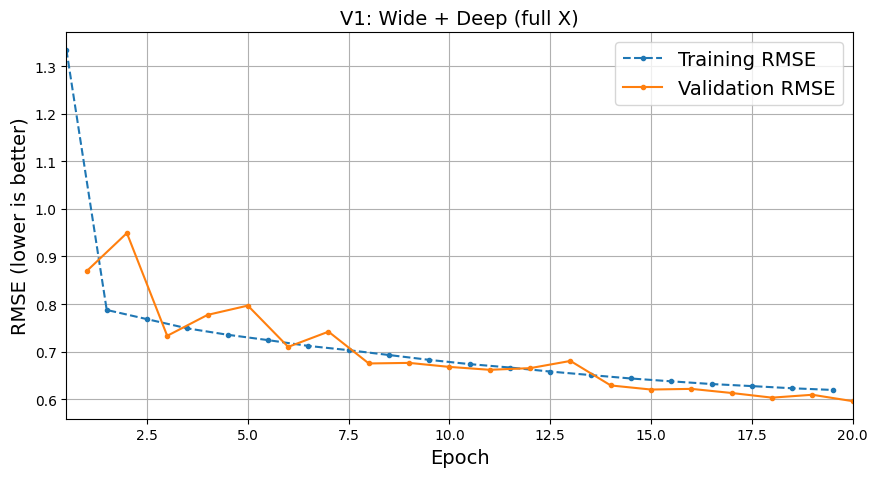

In [17]:
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()  # nn.Module 기능 초기화
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
            nn.Linear(40, 30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + n_features, 1)

    def forward(self, X):
        deep_output = self.deep_stack(X)                 # (배치, 30)
        combined = torch.concat([X, deep_output], dim=1)  # (배치, 38)
        return self.output_layer(combined)              # (배치, 1)

# V1 학습
# 수치를 다시 보고 싶을 때만 이 셀을 재실행한다.
torch.manual_seed(42)
model_v1 = WideAndDeep(n_features).to(device)
optimizer_v1 = torch.optim.SGD(model_v1.parameters(), lr=0.002, momentum=0)
history_v1 = train2(model_v1, optimizer_v1, mse, rmse,
                    train_loader, valid_loader, n_epochs)

predict(model_v1, X_test, y_test, n_samples=5)
plot_learning_curves(history_v1, "V1: Wide + Deep (full X)")

## 05-2. V2: 모델 **안에서** 입력 특성을 나누기

```text
                     입력 X (8)
                      │      │
              ┌───────┘      └─────────────────┐
              ▼                                ▼
       X[:, 2:] (6)                      X[:, :5] (5)
        Deep 경로                          Wide 경로
              │                                │
       Linear(6,50) → ReLU                     │
              ▼                                │
       Linear(50,40) → ReLU                    │
              ▼                                │
       Linear(40,30) → ReLU                    │
              │ (30)                           │ (5)
              └────────► concat ◄─────────────┘
                             │ (35)
                             ▼
                        Linear(35,1)
```

- `X[:, :5]`: 앞의 **5개 열** (Wide)
- `X[:, 2:]`: 앞의 **2개 열을 제외한 6개 열** (Deep)
- 3~5번째 열은 두 경로에 공통으로 포함된다.

Epoch 1/20, train loss: 1.8490, train RMSE: 1.3598, valid RMSE: 0.9100
Epoch 2/20, train loss: 0.6284, train RMSE: 0.7927, valid RMSE: 0.8028
Epoch 3/20, train loss: 0.5762, train RMSE: 0.7591, valid RMSE: 0.7567
Epoch 4/20, train loss: 0.5411, train RMSE: 0.7356, valid RMSE: 0.7290
Epoch 5/20, train loss: 0.5101, train RMSE: 0.7142, valid RMSE: 0.7011
Epoch 6/20, train loss: 0.4842, train RMSE: 0.6958, valid RMSE: 0.6816
Epoch 7/20, train loss: 0.4657, train RMSE: 0.6824, valid RMSE: 0.6670
Epoch 8/20, train loss: 0.4526, train RMSE: 0.6728, valid RMSE: 0.6576
Epoch 9/20, train loss: 0.4439, train RMSE: 0.6662, valid RMSE: 0.6539
Epoch 10/20, train loss: 0.4380, train RMSE: 0.6618, valid RMSE: 0.6498
Epoch 11/20, train loss: 0.4326, train RMSE: 0.6577, valid RMSE: 0.6470
Epoch 12/20, train loss: 0.4285, train RMSE: 0.6546, valid RMSE: 0.6447
Epoch 13/20, train loss: 0.4252, train RMSE: 0.6521, valid RMSE: 0.6452
Epoch 14/20, train loss: 0.4217, train RMSE: 0.6494, valid RMSE: 0.6468
E

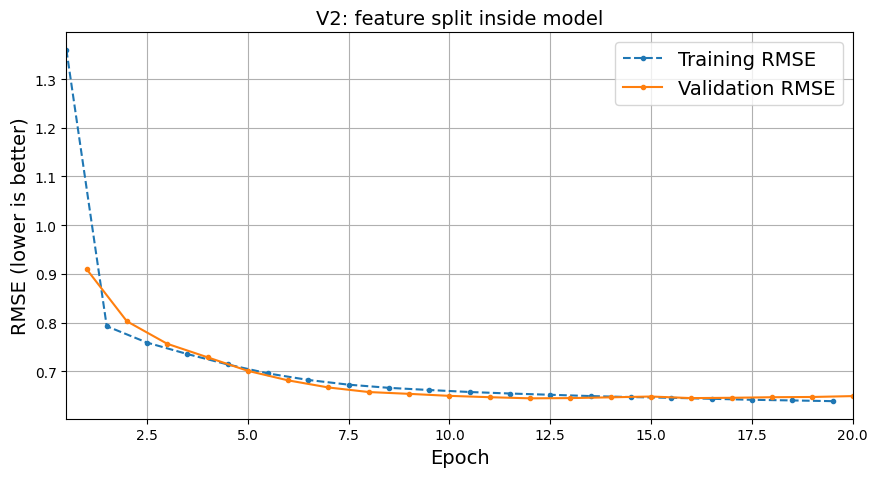

In [18]:
class WideAndDeepV2(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
            nn.Linear(40, 30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + 5, 1)

    def forward(self, X):
        X_wide = X[:, :5]            # 앞의 특성 5개
        X_deep = X[:, 2:]            # 뒤의 특성 6개
        deep_output = self.deep_stack(X_deep)
        combined = torch.concat([X_wide, deep_output], dim=1)  # 5+30=35
        return self.output_layer(combined)

# V2는 forward(X)가 동일하므로 기존 train2(), predict()를 재사용 가능
torch.manual_seed(42)
model_v2 = WideAndDeepV2(n_features).to(device)
optimizer_v2 = torch.optim.SGD(model_v2.parameters(), lr=0.002, momentum=0)
history_v2 = train2(model_v2, optimizer_v2, mse, rmse,
                    train_loader, valid_loader, n_epochs)

predict(model_v2, X_test, y_test, n_samples=5)
plot_learning_curves(history_v2, "V2: feature split inside model")

## 05-3. V3: **두 입력을 따로 받는** 다중 입력 모델

V2와 신경망 구조는 같지만, **나누는 위치**가 다르다. V2는 모델 내부에서 `X`를 분리하고, V3는 **모델 외부**에서 분리한 `X_wide`, `X_deep`를 받는다.

```text
  X_wide (5)                  X_deep (6)
      │                           │
      │                    Linear(6,50) → ReLU
      │                           ▼
      │                    Linear(50,40) → ReLU
      │                           ▼
      │                    Linear(40,30) → ReLU
      │                           │ (30)
      └────────────► concat ◄─────┘
                        │ (35)
                        ▼
                   Linear(35,1)
```

> `model(X_wide, X_deep)`의 **입력 2개**와 `return ...`의 **출력 1개**를 구별하자.

In [19]:
class WideAndDeepV3(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
            nn.Linear(40, 30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + 5, 1)

    # X를 하나가 아니라 Wide/Deep 두 인수로 받는다!
    def forward(self, X_wide, X_deep):
        deep_output = self.deep_stack(X_deep)
        combined = torch.concat([X_wide, deep_output], dim=1)
        return self.output_layer(combined)

# 구조 확인: 학습 전에도 두 입력으로 forward()가 가능한지 확인
torch.manual_seed(42)
model_v3 = WideAndDeepV3(n_features).to(device)
X_wide_demo = X_train[:3, :5].to(device)  # (3, 5)
X_deep_demo = X_train[:3, 2:].to(device)  # (3, 6)
with torch.no_grad():
    demo_pred = model_v3(X_wide_demo, X_deep_demo)
print("입력 형태:", X_wide_demo.shape, X_deep_demo.shape)
print("출력 형태:", demo_pred.shape)  # (3, 1)

# 여기서는 입력 형태만 확인! 실제 V3 훈련은 바로 다음 05-4절에서 진행한다.

입력 형태: torch.Size([3, 5]) torch.Size([3, 6])
출력 형태: torch.Size([3, 1])


## 05-4. 이름 붙은 입력: 사용자 정의 Dataset

`Dataset`에서 `({"X_wide": ..., "X_deep": ...}, y)`를 돌려주면 `DataLoader`가 같은 구조로 배치를 만든다. V3 모델에는 `model(**inputs)` 형태로 전달한다.

| 메서드 | 역할 |
|---|---|
| `__init__()` | 입력·정답 저장 |
| `__len__()` | 샘플 개수 반환 |
| `__getitem__(idx)` | 해당 샘플 하나 반환 |

**`*inputs`**는 위치 인수 묶음, **`**inputs`**는 딕셔너리를 키워드 인수로 펼치는 문법이다. 딕셔너리 키는 `forward(self, X_wide, X_deep)`의 인수명과 정확히 일치해야 한다.

In [20]:
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y

    def __len__(self):
        return len(self.y)  # 전체 샘플 수

    def __getitem__(self, idx):
        # 샘플 하나: (입력 딕셔너리, 타깃)
        inputs = {"X_wide": self.X_wide[idx],
                  "X_deep": self.X_deep[idx]}
        return inputs, self.y[idx]


# Dataset → DataLoader: 훈련/검증/테스트에 동일한 분할 규칙 사용
def make_named_loader(X, y, batch_size=32, shuffle=False):
    dataset = WideAndDeepDataset(X[:, :5], X[:, 2:], y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader_named = make_named_loader(X_train, y_train, shuffle=True)
valid_loader_named = make_named_loader(X_valid, y_valid)
test_loader_named = make_named_loader(X_test, y_test)

# 배치 모양 확인: 이름을 가진 입력 2개 + 정답 1개
inputs_demo, y_demo = next(iter(train_loader_named))
print({key: value.shape for key, value in inputs_demo.items()})
print("정답:", y_demo.shape)

{'X_wide': torch.Size([32, 5]), 'X_deep': torch.Size([32, 6])}
정답: torch.Size([32, 1])


Epoch 1/20, train loss: 0.8380, train RMSE: 0.9154, valid RMSE: 0.6962
Epoch 2/20, train loss: 0.4693, train RMSE: 0.6850, valid RMSE: 0.6647
Epoch 3/20, train loss: 0.4320, train RMSE: 0.6573, valid RMSE: 0.6508
Epoch 4/20, train loss: 0.4181, train RMSE: 0.6466, valid RMSE: 0.6652
Epoch 5/20, train loss: 0.4107, train RMSE: 0.6409, valid RMSE: 0.6525
Epoch 6/20, train loss: 0.4032, train RMSE: 0.6350, valid RMSE: 0.6218
Epoch 7/20, train loss: 0.3968, train RMSE: 0.6299, valid RMSE: 0.6214
Epoch 8/20, train loss: 0.4197, train RMSE: 0.6478, valid RMSE: 0.6226
Epoch 9/20, train loss: 0.3860, train RMSE: 0.6213, valid RMSE: 0.5991
Epoch 10/20, train loss: 0.3828, train RMSE: 0.6187, valid RMSE: 0.6148
Epoch 11/20, train loss: 0.3780, train RMSE: 0.6148, valid RMSE: 0.5920
Epoch 12/20, train loss: 0.3734, train RMSE: 0.6110, valid RMSE: 0.5904
Epoch 13/20, train loss: 0.3651, train RMSE: 0.6042, valid RMSE: 0.6127
Epoch 14/20, train loss: 0.3644, train RMSE: 0.6037, valid RMSE: 0.5822
E

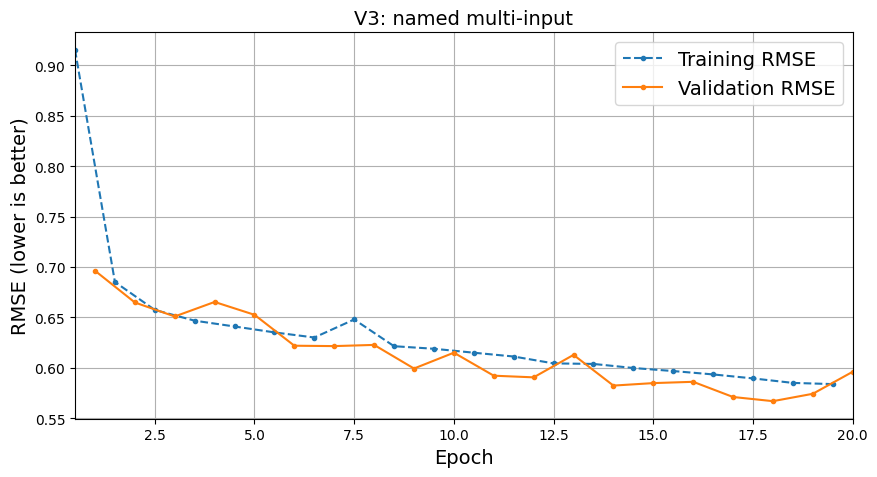

In [21]:
# 딕셔너리 입력을 받는 검증 함수 (V3)
def evaluate_named(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for inputs, y_batch in data_loader:
            inputs = {name: value.to(device) for name, value in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred = model(**inputs)     # model(X_wide=..., X_deep=...)
            metric.update(y_pred, y_batch)
    return metric.compute()


# 딕셔너리 입력으로 학습하는 함수 (V3)
def train_named(model, optimizer, criterion, metric,
                train_loader, valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}

    for epoch in range(n_epochs):
        model.train()
        metric.reset()
        loss_sum, sample_count = 0.0, 0

        for inputs, y_batch in train_loader:
            # Dictionary comprehension: 딕셔너리의 각 텐서를 장치로 이동
            inputs = {name: value.to(device) for name, value in inputs.items()}
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(**inputs)     # 딕셔너리를 풀어 인수 2개 전달
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()

            n = y_batch.size(0)
            loss_sum += loss.item() * n
            sample_count += n
            metric.update(y_pred.detach(), y_batch)

        train_loss = loss_sum / sample_count
        train_rmse = metric.compute().item()
        valid_rmse = evaluate_named(model, valid_loader, metric).item()
        history["train_losses"].append(train_loss)
        history["train_metrics"].append(train_rmse)
        history["valid_metrics"].append(valid_rmse)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {train_loss:.4f}, "
              f"train RMSE: {train_rmse:.4f}, "
              f"valid RMSE: {valid_rmse:.4f}")
    return history


# V3의 두 입력을 딕셔너리로 전달하는 예측 함수
def predict_named(model, X, y, n_samples=5):
    model.eval()
    inputs = {"X_wide": X[:n_samples, :5].to(device),
              "X_deep": X[:n_samples, 2:].to(device)}
    with torch.no_grad():
        y_pred = model(**inputs).cpu()
    print("예측값:\n", y_pred)
    print("실제값:\n", y[:n_samples])
    return y_pred

# V3는 위 05-3에서 생성한 모델을 이어서 학습한다.
optimizer_v3 = torch.optim.SGD(model_v3.parameters(), lr=0.01, momentum=0)
history_v3 = train_named(model_v3, optimizer_v3, mse, rmse,
                         train_loader_named, valid_loader_named, n_epochs)

predict_named(model_v3, X_test, y_test, n_samples=5)
plot_learning_curves(history_v3, "V3: named multi-input")

## 05-5. V4: 주 출력 + 보조 출력

딥 경로가 **스스로도 유용한 특성**을 학습하도록 보조 출력층을 추가한다.

```text
 X_wide (5)                     X_deep (6)
     │                               │
     │                         Deep Stack
     │                               │ (30)
     │                    ┌──────────┴──────────┐
     │                    │                     ▼
     │                    │               Linear(30,1)
     │                    │                     │
     └──────► concat ◄────┘                 보조 출력
                 │ (35)
                 ▼
            Linear(35,1)
                 │
               주 출력

    손실 = 0.8 × 주 출력 MSE + 0.2 × 보조 출력 MSE
    최종 평가 지표(RMSE)는 주 출력만 사용
```

`forward()`는 `(main_output, aux_output)` **튜플**을 반환한다. `loss.backward()`는 두 손실의 가중 합을 기준으로 역전파하며, 공통 Deep 경로는 두 손실에서 모두 그레이디언트를 받는다.

In [22]:
class WideAndDeepV4(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
            nn.Linear(40, 30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + 5, 1)  # 주 출력층
        self.aux_output_layer = nn.Linear(30, 1) # 보조 출력층

    def forward(self, X_wide, X_deep):
        deep_output = self.deep_stack(X_deep)
        combined = torch.concat([X_wide, deep_output], dim=1)
        main_output = self.output_layer(combined)
        aux_output = self.aux_output_layer(deep_output)
        return main_output, aux_output  # 출력 2개

Epoch 1/20, weighted loss: 1.0697, train RMSE: 0.9506, valid RMSE: 0.7085
Epoch 2/20, weighted loss: 0.5811, train RMSE: 0.6946, valid RMSE: 0.6607
Epoch 3/20, weighted loss: 0.5011, train RMSE: 0.6581, valid RMSE: 0.6425
Epoch 4/20, weighted loss: 0.4690, train RMSE: 0.6497, valid RMSE: 0.6654
Epoch 5/20, weighted loss: 0.4503, train RMSE: 0.6420, valid RMSE: 0.6338
Epoch 6/20, weighted loss: 0.4385, train RMSE: 0.6371, valid RMSE: 0.6562
Epoch 7/20, weighted loss: 0.4315, train RMSE: 0.6329, valid RMSE: 0.6191
Epoch 8/20, weighted loss: 0.4248, train RMSE: 0.6301, valid RMSE: 0.6166
Epoch 9/20, weighted loss: 0.4116, train RMSE: 0.6201, valid RMSE: 0.6447
Epoch 10/20, weighted loss: 0.4087, train RMSE: 0.6200, valid RMSE: 0.5939
Epoch 11/20, weighted loss: 0.4073, train RMSE: 0.6197, valid RMSE: 0.5954
Epoch 12/20, weighted loss: 0.3913, train RMSE: 0.6077, valid RMSE: 0.6075
Epoch 13/20, weighted loss: 0.3845, train RMSE: 0.6032, valid RMSE: 0.5835
Epoch 14/20, weighted loss: 0.3837

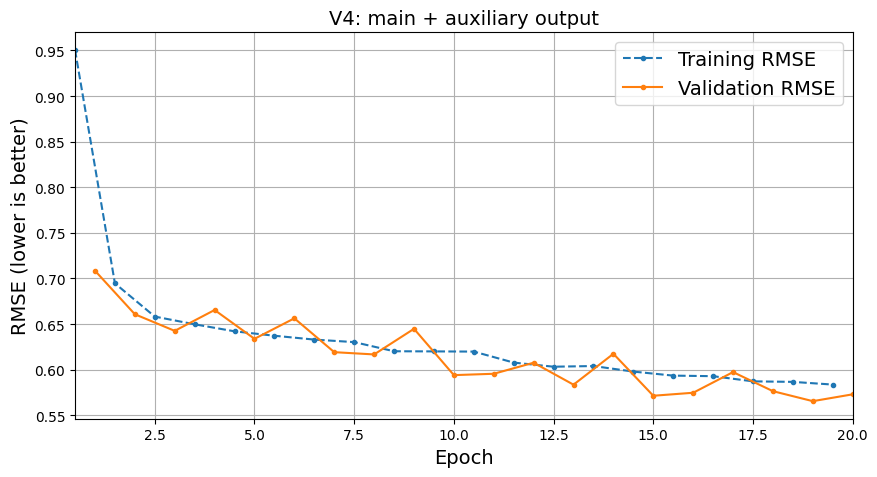

In [23]:
# V4 검증: 두 출력 중 주 출력만 RMSE에 사용
def evaluate_multi_out(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for inputs, y_batch in data_loader:
            inputs = {name: value.to(device) for name, value in inputs.items()}
            y_batch = y_batch.to(device)
            main_pred, _ = model(**inputs)  # _ = 사용하지 않을 보조 출력
            metric.update(main_pred, y_batch)
    return metric.compute()


# V4 훈련: 주 손실과 보조 손실을 하나로 합쳐 역전파
def train_multi_out(model, optimizer, criterion, metric,
                    train_loader, valid_loader, n_epochs, aux_weight=0.2):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}

    for epoch in range(n_epochs):
        model.train()
        metric.reset()
        loss_sum, sample_count = 0.0, 0

        for inputs, y_batch in train_loader:
            inputs = {name: value.to(device) for name, value in inputs.items()}
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            main_pred, aux_pred = model(**inputs)  # 출력 두 개를 풀어 받기
            main_loss = criterion(main_pred, y_batch)
            aux_loss = criterion(aux_pred, y_batch)
            loss = (1 - aux_weight) * main_loss + aux_weight * aux_loss
            loss.backward()                        # 합친 손실에서 역전파
            optimizer.step()

            n = y_batch.size(0)
            loss_sum += loss.item() * n
            sample_count += n
            metric.update(main_pred.detach(), y_batch)  # RMSE는 주 출력만!

        train_loss = loss_sum / sample_count  # V3의 손실과 직접 비교 금지
        train_rmse = metric.compute().item()
        valid_rmse = evaluate_multi_out(model, valid_loader, metric).item()
        history["train_losses"].append(train_loss)
        history["train_metrics"].append(train_rmse)
        history["valid_metrics"].append(valid_rmse)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"weighted loss: {train_loss:.4f}, "
              f"train RMSE: {train_rmse:.4f}, "
              f"valid RMSE: {valid_rmse:.4f}")
    return history


# 학습과 예측
# 모델과 옵티마이저를 새로 만들고, 주 출력만 예측 결과로 사용
torch.manual_seed(42)
model_v4 = WideAndDeepV4(n_features).to(device)
optimizer_v4 = torch.optim.SGD(model_v4.parameters(), lr=0.01, momentum=0)
history_v4 = train_multi_out(model_v4, optimizer_v4, mse, rmse,
                             train_loader_named, valid_loader_named, n_epochs)

model_v4.eval()
X_new = X_test[:5]
inputs_new = {"X_wide": X_new[:, :5].to(device),
              "X_deep": X_new[:, 2:].to(device)}
with torch.no_grad():
    main_pred, _ = model_v4(**inputs_new)  # 보조 출력은 예측에서 제외
print("V4 주 출력 예측:\n", main_pred.cpu())
print("실제 정답:\n", y_test[:5])
plot_learning_curves(history_v4, "V4: main + auxiliary output")

## 05-6. 변형 비교 및 정리

| 모델 | 모델의 입력 | 출력 | 핵심 차이 |
|---|---|---|---|
| V1 | `X` | 1개 | 전체 특성을 Wide와 Deep 양쪽에 사용 |
| V2 | `X` | 1개 | `forward()` 내부에서 Wide 5개 / Deep 6개로 분리 |
| V3 | `X_wide, X_deep` | 1개 | 외부에서 두 입력을 전달 (딕셔너리 가능) |
| V4 | `X_wide, X_deep` | 2개 | 주 출력 + 보조 출력, 손실 가중 합 |

**주의:** V1/V2 학습률은 `0.002`, V3/V4는 `0.01`이다. 이 결과만 보고 구조의 우열을 결론낼 수 없다. V4의 `train_losses`는 가중 합 손실이라 다른 모델의 MSE와 직접 비교하지 않는다.

**암기:** `__init__`에서 층 만들기 → `forward`에서 연결하기 → 여러 입력은 `*`/`**`로 전달 → 여러 출력의 손실은 가중 합 후 `backward()`.

V1 (full X)            | Valid RMSE: 0.5957
V2 (split inside)      | Valid RMSE: 0.6493
V3 (named inputs)      | Valid RMSE: 0.5959
V4 (aux output)        | Valid RMSE: 0.5729


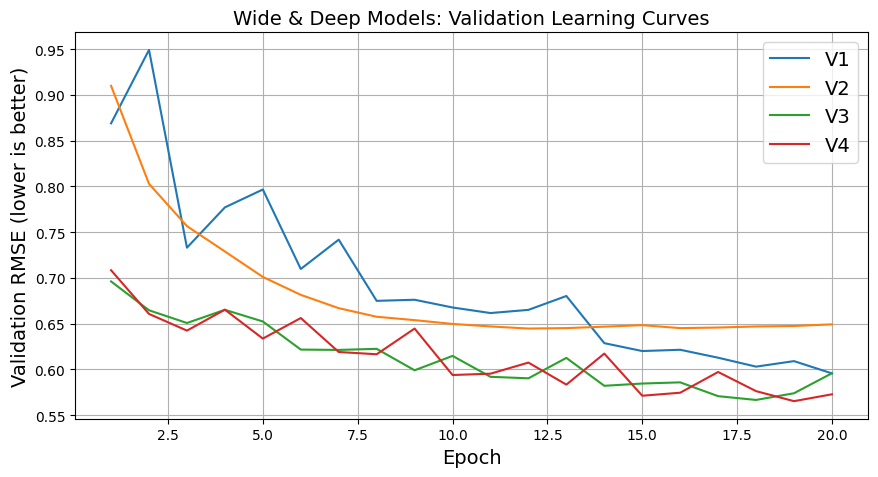

In [24]:
# 위에서 실제로 학습한 모델들의 검증 RMSE를 나란히 확인
results = {
    "V1 (full X)": history_v1["valid_metrics"][-1],
    "V2 (split inside)": history_v2["valid_metrics"][-1],
    "V3 (named inputs)": history_v3["valid_metrics"][-1],
    "V4 (aux output)": history_v4["valid_metrics"][-1],
}

for name, valid_rmse in results.items():
    print(f"{name:22s} | Valid RMSE: {valid_rmse:.4f}")

# 네 모델의 검증 RMSE 학습 곡선을 한 그래프에 비교
plt.figure(figsize=(9, 5))
for label, hist in [("V1", history_v1), ("V2", history_v2),
                    ("V3", history_v3), ("V4", history_v4)]:
    plt.plot(np.arange(len(hist["valid_metrics"])) + 1,
             hist["valid_metrics"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation RMSE (lower is better)")
plt.title("Wide & Deep Models: Validation Learning Curves")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()